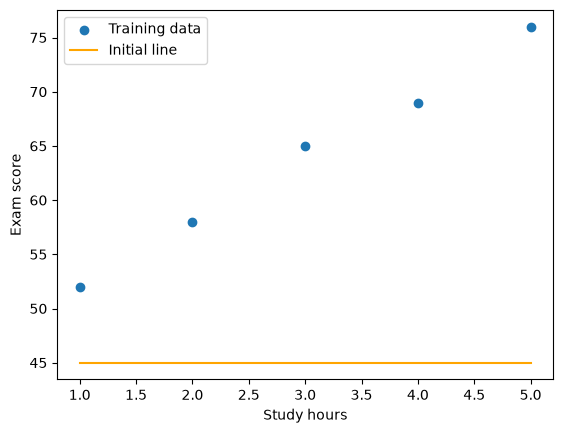

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([1, 2, 3, 4, 5])
y = np.array([52, 58, 65, 69, 76])

w, b = 0.0, 45.0

plt.scatter(x, y, label="Training data")
plt.plot(x, w * x + b, label="Initial line", color="orange")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.legend()
plt.show()

In [2]:
prediction = w * x + b
error = prediction - y
cost = np.mean(error ** 2) / 2

print("每个样本的误差", error)
print("初始成本", cost)

每个样本的误差 [ -7. -13. -20. -24. -31.]
初始成本 215.5


In [3]:
w, b = 0.0, 45.0
alpha = 0.05

cost_history = []
checkpoints = {0: (w, b)}

for step in range(1, 301):
    # 用当前参数计算误差和梯度
    error = w * x + b - y
    dw = np.mean(error * x)
    db = np.mean(error)

    # 先算出两个新值，再一起更新
    new_w = w - alpha * dw
    new_b = b - alpha * db
    w, b = new_w, new_b

    # 记录更新后的成本
    error = w * x + b - y
    cost_history.append(np.mean(error ** 2) / 2)

    if step in (1, 10, 300):
        checkpoints[step] = (w, b)

print("第 1 步的 w 和 b", checkpoints[1])
print("第 300 步的 w 和 b", checkpoints[300])

第 1 步的 w 和 b (np.float64(3.44), np.float64(45.95))
第 300 步的 w 和 b (np.float64(5.893263491413221), np.float64(46.32432093348087))


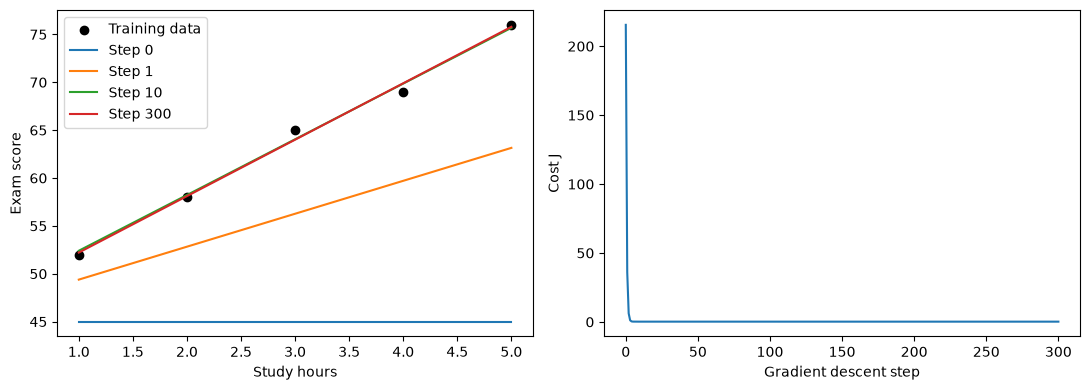

In [4]:
fig, (ax_line, ax_cost) = plt.subplots(1, 2, figsize=(11, 4))

ax_line.scatter(x, y, color="black", label="Training data")
for step, (slope, intercept) in checkpoints.items():
    ax_line.plot(x, slope * x + intercept, label=f"Step {step}")

ax_line.set_xlabel("Study hours")
ax_line.set_ylabel("Exam score")
ax_line.legend()

ax_cost.plot(range(len(cost_history) + 1), [cost] + cost_history)
ax_cost.set_xlabel("Gradient descent step")
ax_cost.set_ylabel("Cost J")

plt.tight_layout()
plt.show()